<a href="https://colab.research.google.com/github/Kurniangga/Praktikum03_Teknik-Regresi-Gambar/blob/main/Praktikum03_Teknik_Regresi_Gambar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Praktikum D1 — Regresi dari Citra Sintetis (Prediksi Radius Lingkaran)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
tf.random.set_seed(42)

IMG_SIZE = 64

def buat_gambar_lingkaran(img_size=64, r_min=5, r_max=20):
    """Buat satu gambar berisi lingkaran putih di latar hitam, radius & posisi acak."""
    img = np.zeros((img_size, img_size), dtype=np.float32)
    r = np.random.uniform(r_min, r_max)
    cx = np.random.uniform(r, img_size - r)
    cy = np.random.uniform(r, img_size - r)

    yy, xx = np.mgrid[0:img_size, 0:img_size]
    mask = (xx - cx)**2 + (yy - cy)**2 <= r**2
    img[mask] = 1.0
    return img, r

def buat_dataset(n_samples, img_size=64, r_min=5, r_max=20):
    X = np.zeros((n_samples, img_size, img_size, 1), dtype=np.float32)
    y = np.zeros((n_samples,), dtype=np.float32)
    for i in range(n_samples):
        img, r = buat_gambar_lingkaran(img_size, r_min, r_max)
        X[i, :, :, 0] = img
        y[i] = r
    return X, y

# Buat dataset train dan test
X_train, y_train = buat_dataset(4000)
X_test, y_test = buat_dataset(800)

print("Bentuk X_train:", X_train.shape)
print("Bentuk y_train:", y_train.shape)
print("Rentang radius:", y_train.min(), "-", y_train.max())

Bentuk X_train: (4000, 64, 64, 1)
Bentuk y_train: (4000,)
Rentang radius: 5.0020204 - 19.995766


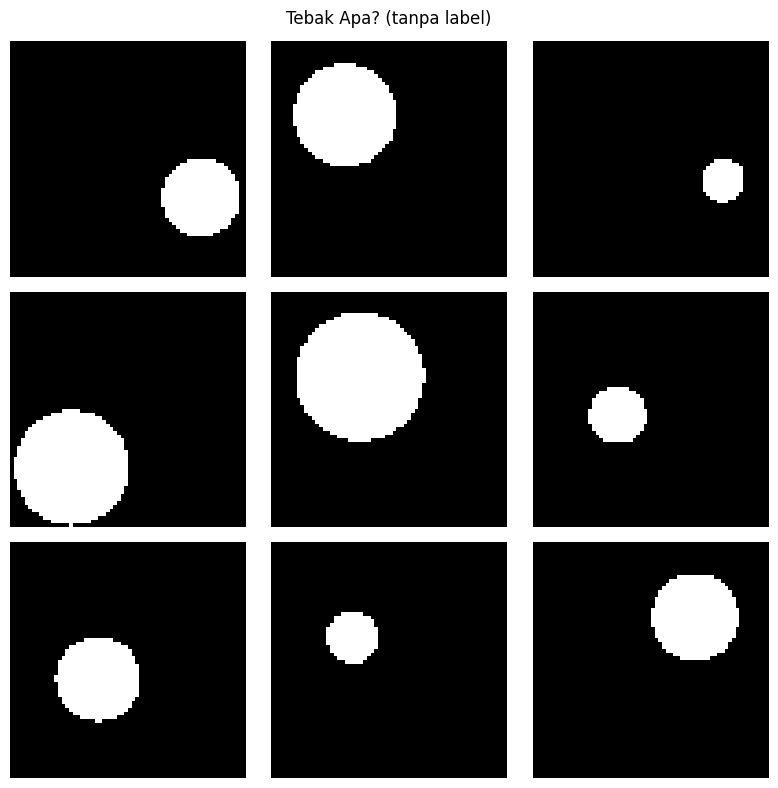

In [2]:
plt.figure(figsize=(8,8))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i,:,:,0], cmap='gray')
    plt.axis('off')
plt.suptitle("Tebak Apa? (tanpa label)")
plt.tight_layout()
plt.show()

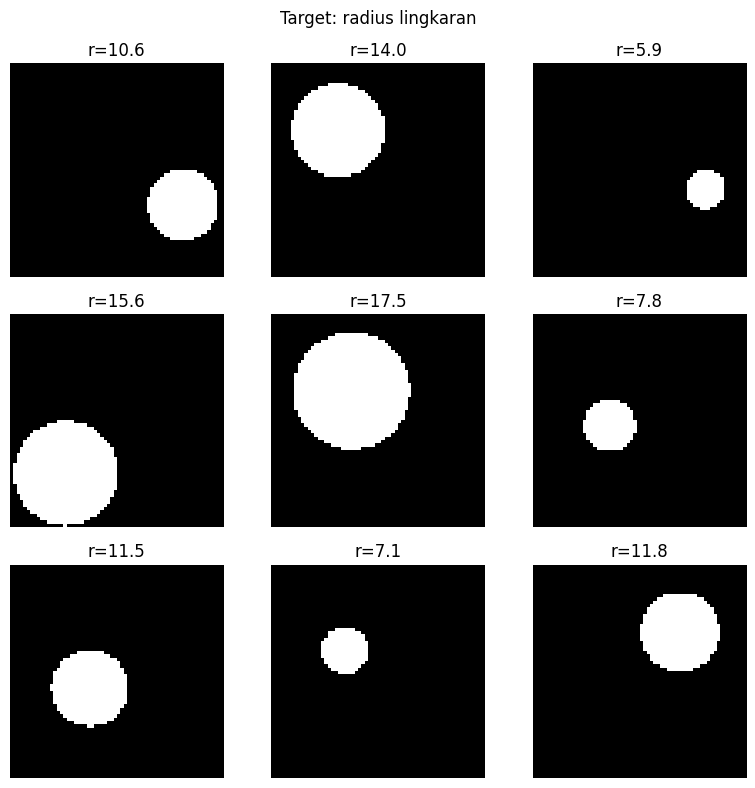

In [3]:
plt.figure(figsize=(8,8))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i,:,:,0], cmap='gray')
    plt.title(f"r={y_train[i]:.1f}")
    plt.axis('off')
plt.suptitle("Target: radius lingkaran")
plt.tight_layout()
plt.show()

In [4]:
model_d1 = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
    layers.Conv2D(16, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)   # output tunggal: nilai radius (regresi, tanpa softmax)
])

model_d1.compile(optimizer='adam',
                 loss='mse',
                 metrics=['mae'])

model_d1.summary()

history_d1 = model_d1.fit(X_train, y_train,
                          validation_split=0.1,
                          epochs=15,
                          batch_size=32)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 406,337 (1.55 MB)

 Trainable params: 406,337 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - loss: 8.9697 - mae: 1.5662 - val_loss: 0.3458 - val_mae: 0.4664
Epoch 2/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3177 - mae: 0.4491 - val_loss: 0.2803 - val_mae: 0.4221
Epoch 3/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2441 - mae: 0.3910 - val_loss: 0.2320 - val_mae: 0.3792
Epoch 4/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2022 - mae: 0.3534 - val_loss: 0.1984 - val_mae: 0.3452
Epoch 5/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1742 - mae: 0.3260 - val_loss: 0.1686 - val_mae: 0.3172
Epoch 6/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1538 - mae: 0.3077 - val_loss: 0.1514 - val_mae: 0.3005
Epoch 7/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1337 - mae: 0.2875 - val_loss: 0.1431 - val_mae: 0.2984
Epoch 8/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1182 - mae: 0.2704 - val_loss: 0.1309 - val_mae: 0.2848
Epoch 9/15
113/113 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - l

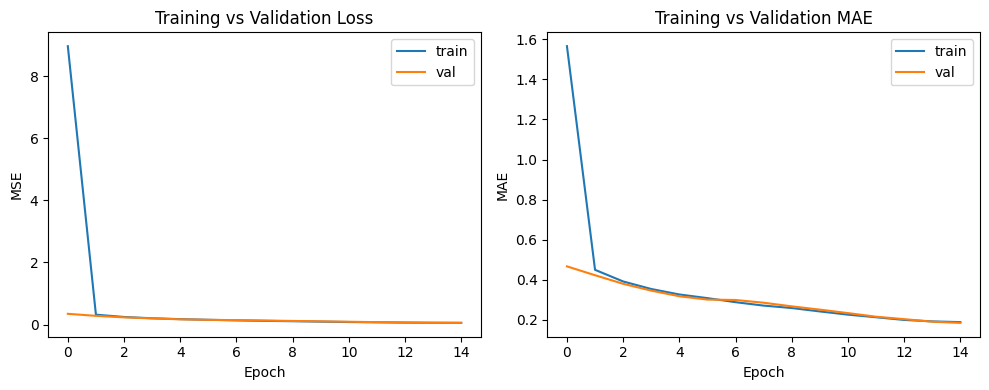

In [5]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history_d1.history['loss'], label='train')
plt.plot(history_d1.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_d1.history['mae'], label='train')
plt.plot(history_d1.history['val_mae'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()

plt.tight_layout()
plt.show()

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step  
MAE  : 0.200
RMSE : 0.255
R²   : 0.997


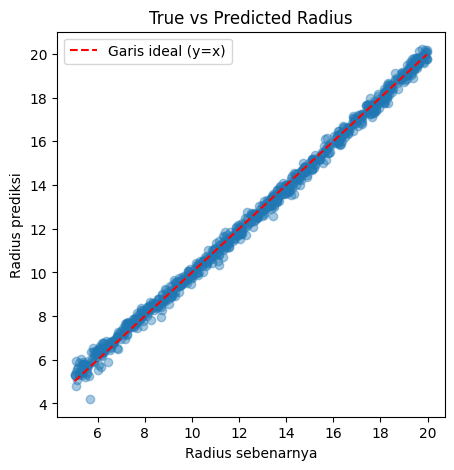

In [6]:
y_pred = model_d1.predict(X_test).flatten()

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

plt.figure(figsize=(5,5))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Garis ideal (y=x)')
plt.xlabel('Radius sebenarnya')
plt.ylabel('Radius prediksi')
plt.title('True vs Predicted Radius')
plt.legend()
plt.show()

Tantangan Mini D1

In [7]:
X_train2, y_train2 = buat_dataset(4000, r_min=8, r_max=28)
X_test2, y_test2 = buat_dataset(800, r_min=8, r_max=28)
# lalu latih ulang model dengan cara yang sama seperti Sel 4-6, bandingkan MAE/RMSE/R²-nya

In [8]:
def tambah_noise(X, std=0.1):
    noise = np.random.normal(0, std, X.shape).astype(np.float32)
    return np.clip(X + noise, 0, 1)

X_train_noisy = tambah_noise(X_train)
X_test_noisy = tambah_noise(X_test)
# latih ulang model dengan X_train_noisy, y_train — bandingkan performa dengan model tanpa noise

Praktikum D2 — Menebak Umur dari Foto Wajah (UTKFace)

In [9]:
from google.colab import files
uploaded = files.upload()  # pilih file kaggle.json

import os
os.makedirs('/root/.kaggle', exist_ok=True)
os.rename('kaggle.json', '/root/.kaggle/kaggle.json')
os.chmod('/root/.kaggle/kaggle.json', 0o600)

!pip install -q kaggle

Saving kaggle.json to kaggle.json


In [10]:
!kaggle datasets download -d jangedoo/utkface-new -p /content/utkface --unzip

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
100% 331M/331M [00:18<00:00, 18.7MB/s]



Jumlah foto: 23708


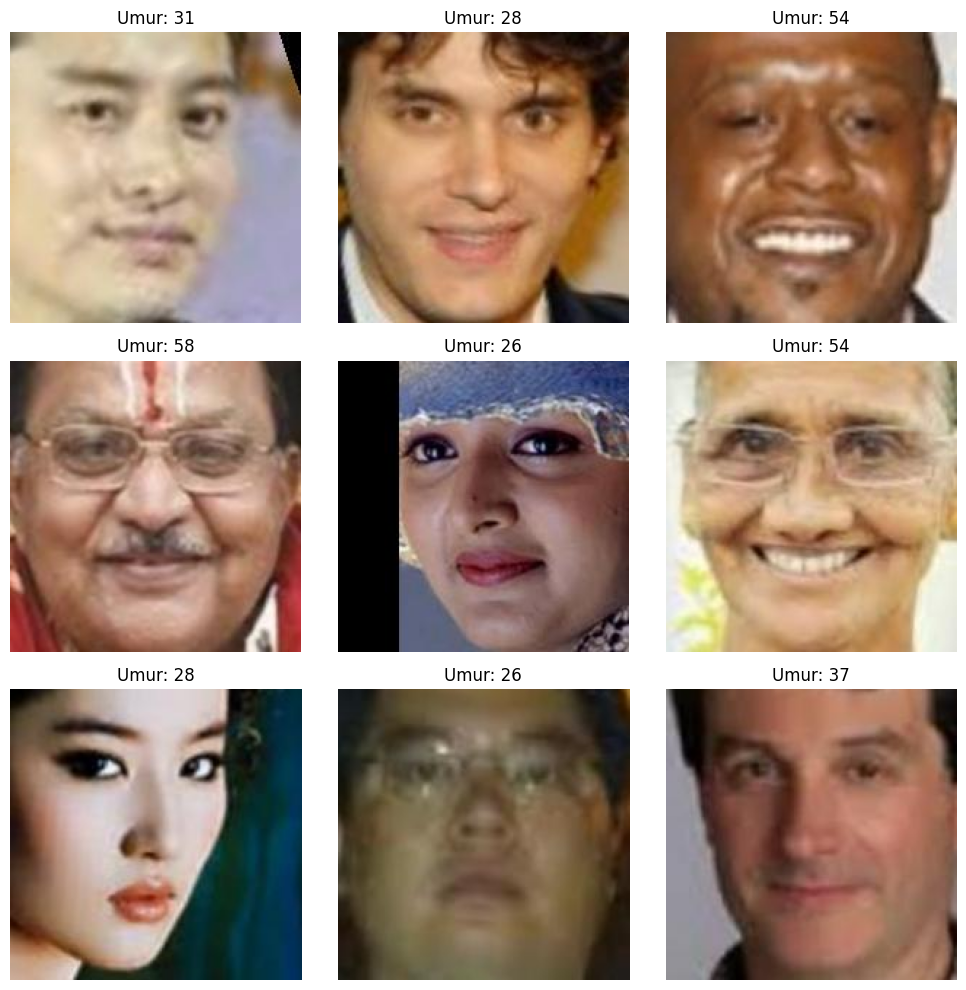

In [11]:
import glob
from PIL import Image

folder_wajah = '/content/utkface/UTKFace'
daftar_file = glob.glob(os.path.join(folder_wajah, '*.jpg'))
print("Jumlah foto:", len(daftar_file))

plt.figure(figsize=(10,10))
for i in range(9):
    fname = daftar_file[i]
    umur = int(os.path.basename(fname).split('_')[0])
    img = Image.open(fname)
    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.title(f"Umur: {umur}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Menyiapkan dataset untuk model (tf.data)

In [12]:
IMG_SIZE = 128

def parse_umur(path):
    fname = os.path.basename(path)
    return int(fname.split('_')[0])

# Ambil label umur dari semua nama file, filter umur yang wajar (0-100)
data_pairs = []
for f in daftar_file:
    try:
        umur = parse_umur(f)
        if 0 <= umur <= 100:
            data_pairs.append((f, umur))
    except Exception:
        continue

print("Total data valid:", len(data_pairs))

np.random.shuffle(data_pairs)
split_idx = int(0.8 * len(data_pairs))
train_pairs = data_pairs[:split_idx]
test_pairs = data_pairs[split_idx:]

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img, label

def buat_tf_dataset(pairs, batch_size=32, shuffle=False):
    paths = [p[0] for p in pairs]
    labels = [p[1] for p in pairs]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(1000)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = buat_tf_dataset(train_pairs, shuffle=True)
test_ds = buat_tf_dataset(test_pairs)

Total data valid: 23687


Membangun model dengan transfer learning (MobileNetV2)

In [13]:
# Gunakan GPU jika tersedia
print("Hardware:", "GPU" if tf.config.list_physical_devices('GPU') else "CPU")

# Buat arsitektur model
base_model = tf.keras.applications.MobileNetV2(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)
base_model.trainable = False  # tahap awal: freeze backbone

# Tambahkan head regresi
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1)(x)  # output tunggal: umur
model_d2 = tf.keras.Model(inputs, outputs)

# Kompilasi model
model_d2.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss='mse', metrics=['mae'])
model_d2.summary()

Hardware: GPU
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Latih Model (Tahap 1 - Frozen)

Epoch 1/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 65s 74ms/step - loss: 193.0581 - mae: 10.4859 - val_loss: 141.8967 - val_mae: 8.9527 - learning_rate: 0.0010
Epoch 2/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - loss: 147.9847 - mae: 9.1159 - val_loss: 130.6434 - val_mae: 8.4801 - learning_rate: 0.0010
Epoch 3/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - loss: 138.6072 - mae: 8.7464 - val_loss: 130.3522 - val_mae: 8.3152 - learning_rate: 0.0010
Epoch 4/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - loss: 134.1617 - mae: 8.5534 - val_loss: 128.5117 - val_mae: 8.1967 - learning_rate: 0.0010
Epoch 5/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 130.2454 - mae: 8.4236 - val_loss: 125.8318 - val_mae: 8.1437 - learning_rate: 0.0010
Epoch 6/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 127.8970 - mae: 8.3454 - val_loss: 121.3077 - val_mae: 8.0739 - learning_rate: 0.0010
Epoch 7/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 13s 22ms/step - loss: 124.3401 - mae: 8.2363 - val_loss: 120.3779 - val

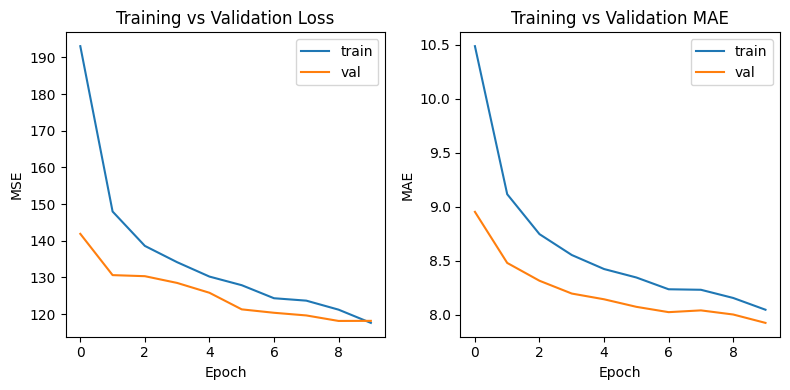

In [14]:
cb = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss'),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5, monitor='val_loss')
]

history_d2 = model_d2.fit(
    train_ds, validation_data=test_ds, epochs=10,
    callbacks=cb, verbose=1
)

# Visualisasi loss dan MAE selama pelatihan
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history_d2.history['loss'], label='train')
plt.plot(history_d2.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_d2.history['mae'], label='train')
plt.plot(history_d2.history['val_mae'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()

plt.tight_layout()
plt.show()

Fine-tuning backbone (Tahap 2)

In [16]:
base_model.trainable = True

# Bekukan sebagian besar lapisan awal, buka lapisan-lapisan akhir saja
for layer in base_model.layers[:-30]:
    layer.trainable = False

model_d2.compile(optimizer=tf.keras.optimizers.Adam(1e-5),  # learning rate kecil untuk fine-tuning
                 loss='mse', metrics=['mae'])

history_d2_ft = model_d2.fit(
    train_ds, validation_data=test_ds, epochs=10,
    callbacks=cb, verbose=1
)

Epoch 1/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 48s 51ms/step - loss: 165.1698 - mae: 9.7380 - val_loss: 144.5957 - val_mae: 8.9078 - learning_rate: 1.0000e-05
Epoch 2/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - loss: 134.8794 - mae: 8.8162 - val_loss: 132.1997 - val_mae: 8.5369 - learning_rate: 1.0000e-05
Epoch 3/10
593/593 ━━━━━━━━━━━━━━━━━━━━ 15s 25ms/step - loss: 119.4825 - mae: 8.3026 - val_loss: 120.7725 - val_mae: 8.1541 - learning_rate: 1.0000e-05


Evaluasi akhir (MAE, RMSE, R²)

MAE  : 8.908 tahun
RMSE : 12.025 tahun
R²   : 0.619


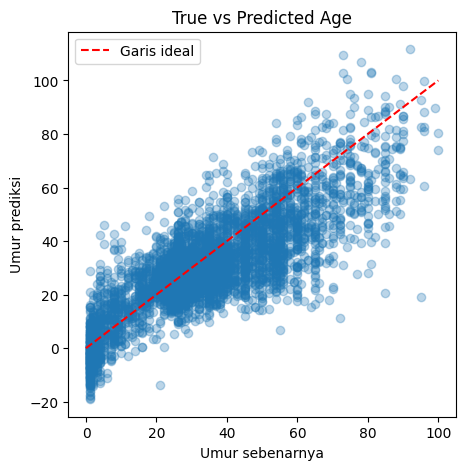

In [17]:
y_true_list = []
y_pred_list = []

for imgs, labels in test_ds:
    preds = model_d2.predict(imgs, verbose=0).flatten()
    y_true_list.extend(labels.numpy())
    y_pred_list.extend(preds)

y_true_arr = np.array(y_true_list)
y_pred_arr = np.array(y_pred_list)

mae = mean_absolute_error(y_true_arr, y_pred_arr)
rmse = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
r2 = r2_score(y_true_arr, y_pred_arr)

print(f"MAE  : {mae:.3f} tahun")
print(f"RMSE : {rmse:.3f} tahun")
print(f"R²   : {r2:.3f}")

plt.figure(figsize=(5,5))
plt.scatter(y_true_arr, y_pred_arr, alpha=0.3)
plt.plot([0,100],[0,100],'r--', label='Garis ideal')
plt.xlabel('Umur sebenarnya')
plt.ylabel('Umur prediksi')
plt.title('True vs Predicted Age')
plt.legend()
plt.show()

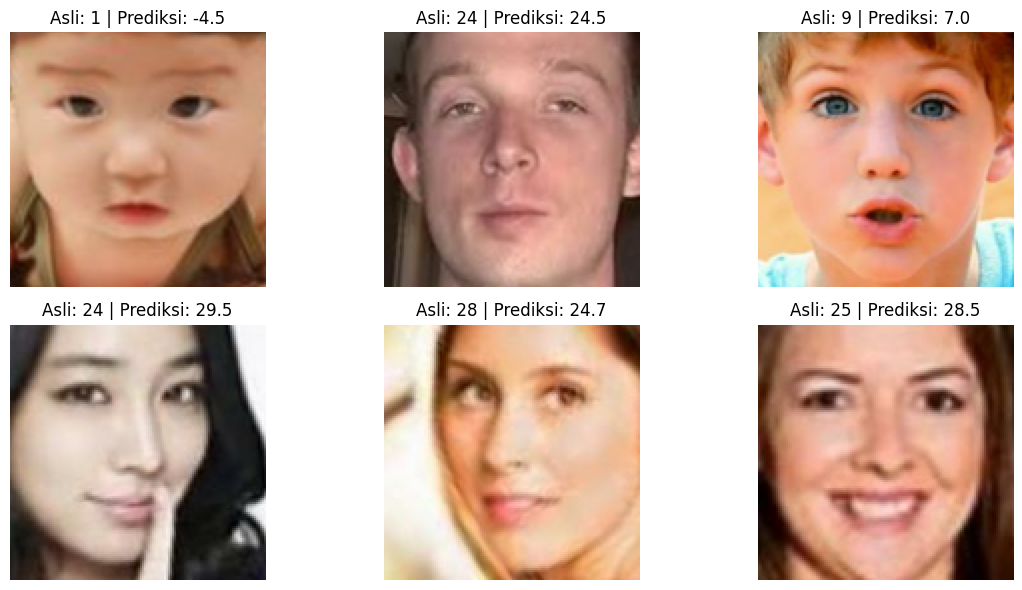

In [18]:
for imgs, labels in test_ds.take(1):
    preds = model_d2.predict(imgs, verbose=0).flatten()
    plt.figure(figsize=(12,6))
    for i in range(min(6, len(imgs))):
        plt.subplot(2,3,i+1)
        plt.imshow(imgs[i].numpy())
        plt.title(f"Asli: {labels[i].numpy()} | Prediksi: {preds[i]:.1f}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    break

Praktikum D3 — Menilai "Kepopuleran Hewan Peliharaan" (Pawpularity)

In [21]:
from google.colab import files
files.upload()  # pilih kaggle.json dari komputer Anda
import os, shutil
if os.path.exists("kaggle.json"):
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
    os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
    !pip -q install kaggle
    print("✅ Kaggle API siap digunakan.")
else:
    print("⚠️ kaggle.json belum ditemukan. Upload terlebih dahulu.")

Saving kaggle.json to kaggle.json
✅ Kaggle API siap digunakan.


In [24]:
!kaggle competitions download -c petfinder-pawpularity-score -p /content/paw
!unzip -q /content/paw/petfinder-pawpularity-score.zip -d /content/paw

100% 983M/983M [00:46<00:00, 22.4MB/s]



Lihat Contoh Data

In [25]:
import pandas as pd

df = pd.read_csv('/content/paw/train.csv')
print(df.shape)
df.head()

(9912, 14)


,Id,Subject Focus,Eyes,Face,Near,Action,Accessory,Group,Collage,Human,Occlusion,Info,Blur,Pawpularity
0,0007de18844b0dbbb5e1f607da0606e0,0,1,1,1,0,0,1,0,0,0,0,0,63
1,0009c66b9439883ba2750fb825e1d7db,0,1,1,0,0,0,0,0,0,0,0,0,42
2,0013fd999caf9a3efe1352ca1b0d937e,0,1,1,1,0,0,0,0,1,1,0,0,28
3,0018df346ac9c1d8413cfcc888ca8246,0,1,1,1,0,0,0,0,0,0,0,0,15
4,001dc955e10590d3ca4673f034feeef2,0,0,0,1,0,0,1,0,0,0,0,0,72


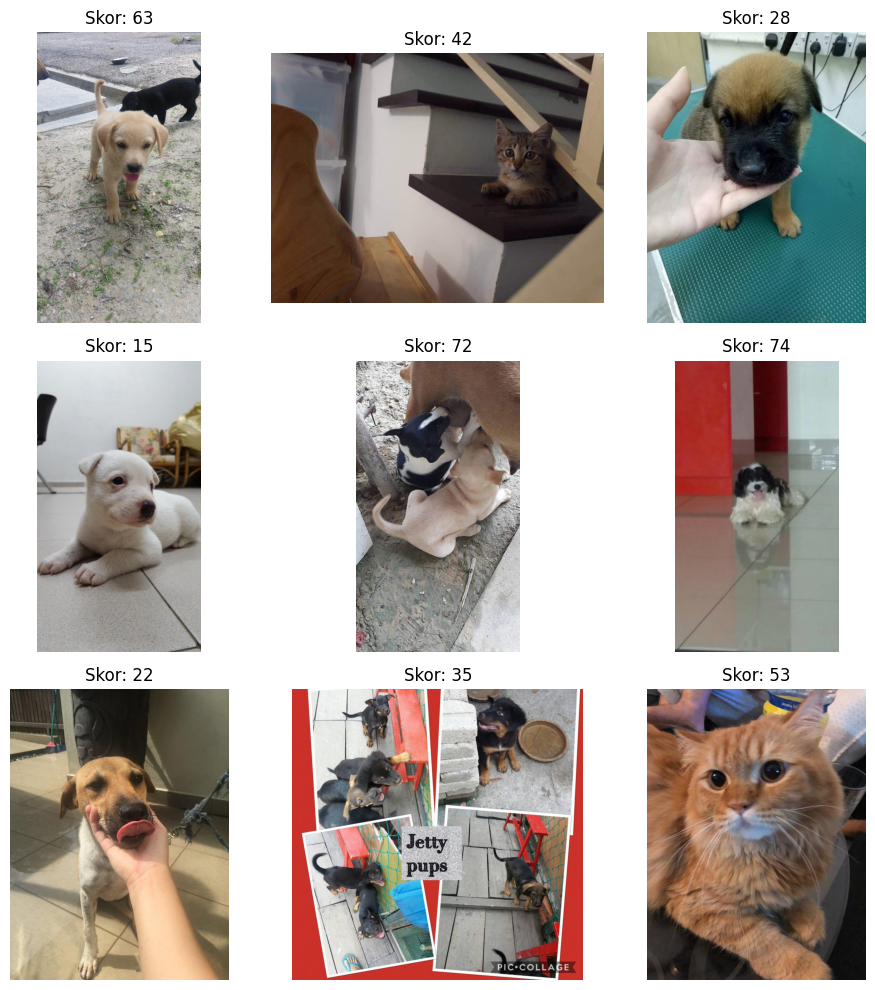

In [26]:
folder_paw = '/content/paw/train'

plt.figure(figsize=(10,10))
for i in range(9):
    row = df.iloc[i]
    img_path = os.path.join(folder_paw, row['Id'] + '.jpg')
    img = Image.open(img_path)
    plt.subplot(3,3,i+1)
    plt.imshow(img)
    plt.title(f"Skor: {row['Pawpularity']}")
    plt.axis('off')
plt.tight_layout()
plt.show()

Persiapan Data

In [27]:
IMG_SIZE = 224  # EfficientNetB0 biasanya pakai 224x224

df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
split_idx = int(0.8 * len(df_shuffled))
train_df = df_shuffled.iloc[:split_idx]
val_df = df_shuffled.iloc[split_idx:]

def load_paw_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img, label

def buat_paw_dataset(df_subset, batch_size=32, shuffle=False):
    paths = [os.path.join(folder_paw, id_ + '.jpg') for id_ in df_subset['Id']]
    labels = df_subset['Pawpularity'].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(1000)
    ds = ds.map(load_paw_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds_paw = buat_paw_dataset(train_df, shuffle=True)
val_ds_paw = buat_paw_dataset(val_df)

In [28]:
base_model_paw = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)
base_model_paw.trainable = False

inputs_paw = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs_paw * 255.0)
x = base_model_paw(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs_paw = layers.Dense(1)(x)  # skor pawpularity, kontinu

model_d3 = tf.keras.Model(inputs_paw, outputs_paw)

model_d3.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                 loss='mse', metrics=['mae'])
model_d3.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Latih model

In [30]:
cb_paw = [
    tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, monitor='val_loss'),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-6, monitor='val_loss')
]

history_d3 = model_d3.fit(
    train_ds_paw, validation_data=val_ds_paw,
    epochs=10, callbacks=cb_paw, verbose=1
)

Epoch 1/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 38s 155ms/step - loss: 438.6842 - mae: 15.4022 - val_loss: 454.5164 - val_mae: 15.5088 - learning_rate: 0.0010
Epoch 2/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 36s 143ms/step - loss: 430.6715 - mae: 15.2183 - val_loss: 449.7428 - val_mae: 15.4498 - learning_rate: 0.0010
Epoch 3/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 38s 155ms/step - loss: 427.6187 - mae: 15.2194 - val_loss: 445.5269 - val_mae: 15.4025 - learning_rate: 0.0010
Epoch 4/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 38s 143ms/step - loss: 427.0099 - mae: 15.1869 - val_loss: 441.5770 - val_mae: 15.3603 - learning_rate: 0.0010
Epoch 5/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 41s 142ms/step - loss: 418.9019 - mae: 15.0988 - val_loss: 437.6220 - val_mae: 15.2946 - learning_rate: 0.0010
Epoch 6/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 34s 138ms/step - loss: 419.2130 - mae: 15.0989 - val_loss: 434.6623 - val_mae: 15.2467 - learning_rate: 0.0010
Epoch 7/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 35s 143ms/step - loss: 415.6885 - mae: 14.9979 - val_l

Lihat proses belajar

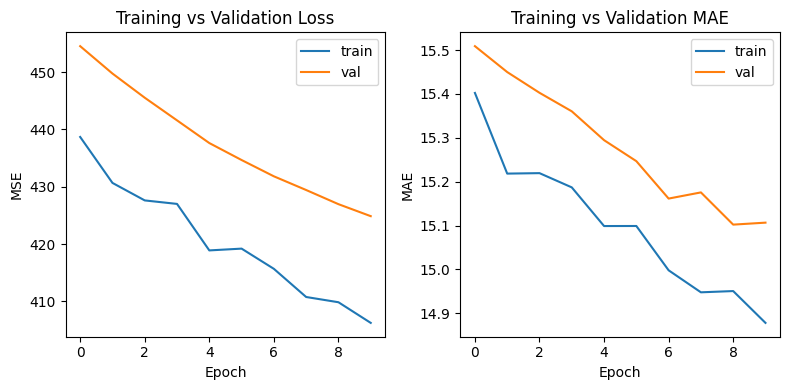

In [31]:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history_d3.history['loss'], label='train')
plt.plot(history_d3.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history_d3.history['mae'], label='train')
plt.plot(history_d3.history['val_mae'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MAE'); plt.title('Training vs Validation MAE')
plt.legend()

plt.tight_layout()
plt.show()

Evaluasi model

MAE  : 15.107
RMSE : 20.612
R²   : 0.008


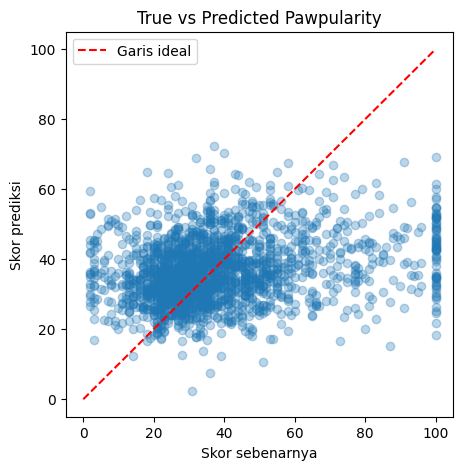

In [32]:
y_true_paw, y_pred_paw = [], []
for imgs, labels in val_ds_paw:
    preds = model_d3.predict(imgs, verbose=0).flatten()
    y_true_paw.extend(labels.numpy())
    y_pred_paw.extend(preds)

y_true_paw = np.array(y_true_paw)
y_pred_paw = np.array(y_pred_paw)

mae = mean_absolute_error(y_true_paw, y_pred_paw)
rmse = np.sqrt(mean_squared_error(y_true_paw, y_pred_paw))
r2 = r2_score(y_true_paw, y_pred_paw)

print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

plt.figure(figsize=(5,5))
plt.scatter(y_true_paw, y_pred_paw, alpha=0.3)
plt.plot([0,100],[0,100],'r--', label='Garis ideal')
plt.xlabel('Skor sebenarnya')
plt.ylabel('Skor prediksi')
plt.title('True vs Predicted Pawpularity')
plt.legend()
plt.show()

Lihat contoh prediksi

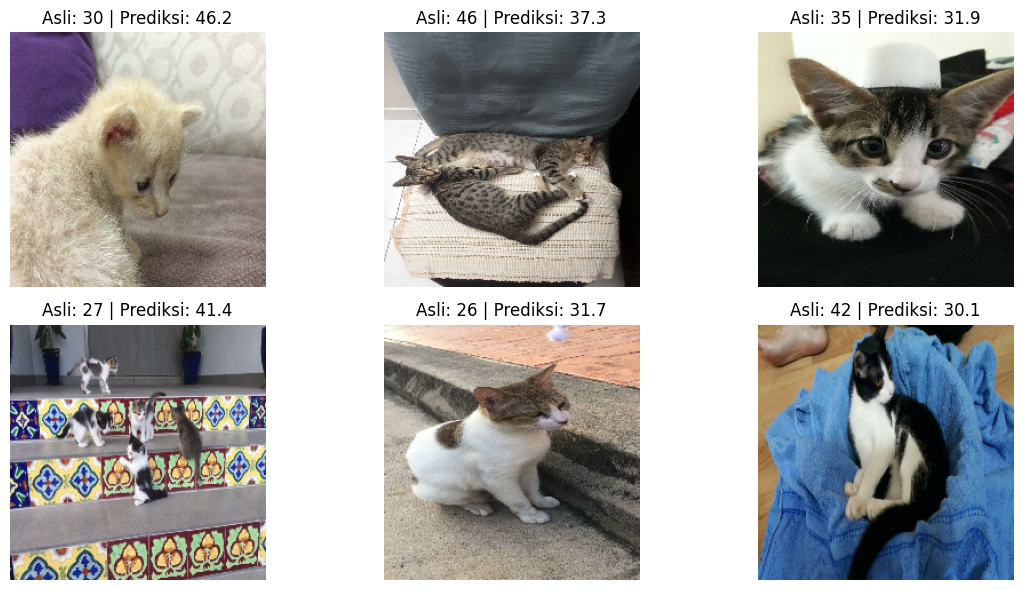

In [33]:
for imgs, labels in val_ds_paw.take(1):
    preds = model_d3.predict(imgs, verbose=0).flatten()
    plt.figure(figsize=(12,6))
    for i in range(min(6, len(imgs))):
        plt.subplot(2,3,i+1)
        plt.imshow(imgs[i].numpy())
        plt.title(f"Asli: {labels[i].numpy():.0f} | Prediksi: {preds[i]:.1f}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    break

Poin 3: Uji prediksi usia dengan foto wajah pribadi

In [38]:
from google.colab import files
uploaded_wajah = files.upload()  # pilih foto wajahmu

Saving angga.jpeg to angga.jpeg


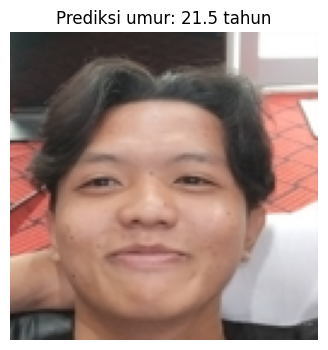

angga.jpeg -> prediksi umur: 21.5 tahun


In [39]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

IMG_SIZE_D2 = 128  # samakan dengan ukuran input model_d2 di D2

def prediksi_umur(fname, model):
    img = Image.open(fname).convert('RGB')
    img_resized = img.resize((IMG_SIZE_D2, IMG_SIZE_D2))
    arr = np.array(img_resized).astype('float32') / 255.0
    arr_batch = np.expand_dims(arr, axis=0)  # (1, H, W, 3)

    pred_umur = model.predict(arr_batch, verbose=0)[0][0]

    plt.figure(figsize=(4,4))
    plt.imshow(img_resized)
    plt.title(f"Prediksi umur: {pred_umur:.1f} tahun")
    plt.axis('off')
    plt.show()

    return pred_umur

for fname in uploaded_wajah.keys():
    hasil = prediksi_umur(fname, model_d2)
    print(f"{fname} -> prediksi umur: {hasil:.1f} tahun")

Poin 4: Uji prediksi Pawpularity dengan foto pribadi/hewan peliharaan

In [40]:
uploaded_paw = files.upload()  # pilih foto hewan peliharaan atau fotomu

Saving boni.jpeg to boni.jpeg


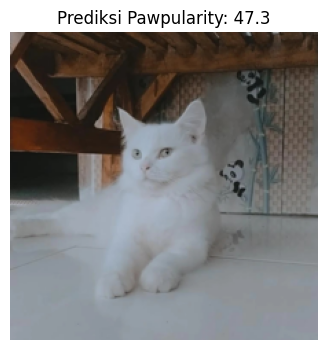

boni.jpeg -> prediksi Pawpularity: 47.3


In [41]:
IMG_SIZE_D3 = 224  # samakan dengan ukuran input model_d3

def prediksi_pawpularity(fname, model):
    img = Image.open(fname).convert('RGB')
    img_resized = img.resize((IMG_SIZE_D3, IMG_SIZE_D3))
    arr = np.array(img_resized).astype('float32') / 255.0
    arr_batch = np.expand_dims(arr, axis=0)

    pred_skor = model.predict(arr_batch, verbose=0)[0][0]

    plt.figure(figsize=(4,4))
    plt.imshow(img_resized)
    plt.title(f"Prediksi Pawpularity: {pred_skor:.1f}")
    plt.axis('off')
    plt.show()

    return pred_skor

for fname in uploaded_paw.keys():
    hasil = prediksi_pawpularity(fname, model_d3)
    print(f"{fname} -> prediksi Pawpularity: {hasil:.1f}")